# The fan effect with symbolic and embedded chunk contents

The fan effect (Anderson, 1974) is a good test for an embedded representation in PRIMs.
In ACT-R and PRIMs it comes from one specific mechanism: the association from a cue
*j* to a fact *i* is S<sub>ji</sub> = mas − ln(fan<sub>j</sub>), so the more facts share
a cue, the less activation each gets. If chunk contents become vectors, the question
is which part of that mechanism the vectors can take over, and what they add.

This notebook runs one PRIMs model of the person–location task under several
representations and asks six questions:

1. **Baseline.** Does the symbolic model reproduce the data?
2. **The limit.** Does the embedded model reduce exactly to the symbolic one?
3. **For free?** Does partial matching on embeddings give a fan effect by itself?
4. **Associations from similarity.** If S<sub>ji</sub> comes from similarity, what changes?
5. **What embeddings add.** Similar cues, related facts and memory size.
6. **Categories.** Does it help if persons resemble persons and locations resemble locations?

**Every prediction is an average over 20 model runs** (simulated participants with
different random seeds and, for embedded models, their own random vectors), as is usual
for ACT-R models. Error bars are ±1 standard error over runs. The runs are spread over
all cores; the whole notebook takes about 12 minutes on 2 cores (half of it for section 6) and proportionally less
on more. Set `RUNS` lower in the next cell for a quick look.

The model is in `fan.py` next to this notebook; the representation is documented in
`../EMBEDDINGS.md`.

In [1]:
import math, os, statistics, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(".."))      # pyprims, if not installed
sys.path.insert(0, os.path.abspath("."))       # fan.py
import fan
from pyprims import Model
from pyprims.embedding import Embedded, Embedding

RUNS = 20            # model runs (simulated participants) averaged per setting
PROCESSES = None     # None: use every core; 1: run serially

def many(task_kw, rep=None, **kw):
    # average of RUNS model runs; rep is a representation spec (see fan.build_representation)
    return fan.run_many(task_kw, rep, runs=RUNS, processes=PROCESSES, **kw)

def similarity_spec(beta, **extra):
    return dict(compare="symbolic", retrieval="symbolic", spreading="similarity", beta=beta, **extra)

def se(xs):
    xs = [x for x in xs if not math.isnan(x)]
    return statistics.stdev(xs) / math.sqrt(len(xs)) if len(xs) > 1 else math.nan

print(f"{RUNS} runs per setting, {PROCESSES or os.cpu_count()} processes")

# chart style: one hue per location fan (fixed order), recessive grid, thin marks
C = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.8, "lines.linewidth": 2, "font.size": 10})

20 runs per setting, 2 processes


## The data and the task

Participants studied 26 sentences such as *the hippie is in the park* and then verified
probes: **targets** (studied pairs) and **foils** (a studied person with a studied
location they were not paired with). The person and the location each appeared in one,
two or three sentences, and verification time grows with both fans.

The data are Anderson's (1974) Table 5: mean verification times and error rates,
averaged over his Experiments 1 and 2 and the no-precue condition of Experiment 3
(63 participants, 432 observations per cell). The ACT-R tutorial (Unit 5) gives the
same times rounded to 10 ms.

> Anderson, J. R. (1974). Retrieval of propositional information from long-term memory.
> *Cognitive Psychology, 6*, 451–474.

In [2]:
def table(d, fmt="{:.3f}"):
    rows = ["              person fan 1      2      3"]
    for l in (1, 2, 3):
        rows.append(f"location fan {l}:   " + "  ".join(fmt.format(d[(p, l)]) for p in (1, 2, 3)))
    return "\n".join(rows)

for kind, name in (("target", "trues"), ("foil", "falses")):
    print(f"{name}: verification time (s)\n" + table(fan.DATA[kind]))
    print(f"{name}: error rate\n" + table(fan.ERRORS[kind], "{:5.1%}") + "\n")

trues: verification time (s)
              person fan 1      2      3
location fan 1:   1.111  1.174  1.222
location fan 2:   1.167  1.198  1.222
location fan 3:   1.153  1.233  1.357
trues: error rate
              person fan 1      2      3
location fan 1:    5.1%   4.2%   4.6%
location fan 2:    6.5%   5.6%   6.0%
location fan 3:    6.3%   4.4%   5.4%

falses: verification time (s)
              person fan 1      2      3
location fan 1:   1.197  1.221  1.264
location fan 2:   1.250  1.356  1.291
location fan 3:   1.262  1.471  1.465
falses: error rate
              person fan 1      2      3
location fan 1:    1.9%   4.2%   3.0%
location fan 2:    1.4%   3.7%   4.4%
location fan 3:    4.2%   7.9%   5.1%



The model studies 24 facts (`fan.FACTS`); every person-fan × location-fan cell from
1×1 to 3×3 occurs at least once. Foils are unstudied recombinations, up to two per cell.

In [3]:
pf, lf = fan.fans()
print("facts:", ", ".join(f"{p}–{l}" for p, l in fan.FACTS))
print("\nperson fans:  ", pf)
print("location fans:", lf)
plist = fan.probes()
print(f"\n{sum(p[2] == 'target' for p in plist)} target probes, {sum(p[2] == 'foil' for p in plist)} foil probes")

facts: hippie–dungeon, captain–garden, debutante–park, fireman–museum, giant–harbor, giant–store, earl–garden, earl–museum, lawyer–castle, lawyer–church, doctor–harbor, doctor–beach, sailor–museum, sailor–dungeon, sailor–forest, teacher–cave, teacher–forest, teacher–garden, banker–store, banker–beach, banker–castle, farmer–harbor, farmer–bank, farmer–store

person fans:   {'hippie': 1, 'captain': 1, 'debutante': 1, 'fireman': 1, 'giant': 2, 'earl': 2, 'lawyer': 2, 'doctor': 2, 'sailor': 3, 'teacher': 3, 'banker': 3, 'farmer': 3}
location fans: {'dungeon': 2, 'garden': 3, 'park': 1, 'museum': 3, 'harbor': 3, 'store': 3, 'castle': 2, 'church': 1, 'beach': 2, 'forest': 2, 'cave': 1, 'bank': 1}

24 target probes, 18 foil probes


### The PRIMs model

Five operators. The retrieval request only asks for a fact (`in -> RT1`); the probe's
person and location are in the input buffer (V1, V2) and **spread activation** to the
facts that contain them. The retrieved fact is then checked against the probe:

| operator | conditions | actions |
|---|---|---|
| retrieve-fact | V1 <> nil, WM1 = nil | V1 -> WM1, in -> RT1 |
| respond-yes | RT2 = V1, RT3 = V2 | press yes |
| respond-no-person | RT2 <> V1 | press no |
| respond-no-location | RT3 <> V2 | press no |
| respond-no-failure | RT1 = error | press no |

For a target the studied fact gets spreading from both cues and is usually retrieved.
For a foil the best fact shares only one cue, so it is less active and therefore slower
to retrieve, and the mismatch makes the model say no. Here is one trial of each:

In [4]:
m = Model(seed=2, trace=True)
m.load(fan.make_task())
m.time += 300                      # let the study-phase base levels settle
for probe in [("sailor", "museum", "target", 3, 3), ("sailor", "park", "foil", 3, 1)]:
    m.current_probe = probe
    m.run_trial()
    print(f"--- {probe[2]}: {probe[0]} in {probe[1]}  ->  {m.probe_response}")
    print(m.get_trace(2))

--- target: sailor in museum  ->  yes
300.00  Starting new trial
300.03  *** Retrieved operator retrieve-fact with latency 0.034
300.98  Retrieving f13 (latency = 0.292)
301.29  *** Retrieved operator respond-yes with latency 0.013
302.24  pressing yes  (latency = 0.200)
302.44  End of trial

--- foil: sailor in park  ->  no
303.44  Starting new trial
303.48  *** Retrieved operator retrieve-fact with latency 0.036
304.43  Retrieving f3 (latency = 0.275)
304.71  *** Retrieved operator respond-no-person with latency 0.013
305.36  pressing no  (latency = 0.200)
305.56  End of trial



## 1. Baseline: the symbolic model

A small grid over the maximum associative strength (`mas`) and the latency factor
(`lf`), with one free intercept (the model's perceptual and motor times are not
calibrated to this experiment). Each setting is run 20 times and the fit uses the
averaged predictions for the 18 cells. For comparison the cell also shows how well
*single* runs fit; selecting parameters on a single run would capitalise on its noise.

In [5]:
grid = {}
for mas in (1.5, 2.0, 2.5):
    for lf_ in (0.6, 0.8, 1.0):
        grid[(mas, lf_)] = many(dict(mas=mas, lf=lf_))
ranked = sorted(grid.items(), key=lambda kv: kv[1].fit()["rmsd"])
print(f"                 {RUNS}-run average          single runs")
for (mas, lf_), res in ranked[:5]:
    f, single = res.fit(), res.run_rmsds()
    print(f"mas {mas:.1f}  lf {lf_:.1f}   RMSD {1000 * f['rmsd']:3.0f} ms  r = {f['r']:.3f}"
          f"     RMSD {1000 * statistics.mean(single):3.0f} ms (range {1000 * min(single):.0f}-{1000 * max(single):.0f})")
(MAS, LF), SYM = ranked[0]
sym_fit = SYM.fit()
cell_se = statistics.mean(v["se"] for v in SYM.cells.values())
print(f"\nbest: mas = {MAS}, lf = {LF}; intercept shift {sym_fit['shift']:.2f} s;",
      f"target errors {statistics.mean(v['err'] for k, v in SYM.cells.items() if k[0] == 'target'):.1%};",
      f"standard error of a cell mean {1000 * cell_se:.1f} ms")

def interaction(get):
    # Anderson's test of the race model: the effect of one fan (1 -> 3) when the other
    # fan is held at 1, 2 or 3, averaged over persons/locations and trues/falses
    out = []
    for other in (1, 2, 3):
        e = [get(k, 3, other) - get(k, 1, other) for k in ("target", "foil")]
        e += [get(k, other, 3) - get(k, other, 1) for k in ("target", "foil")]
        out.append(1000 * statistics.mean(e))
    return out

kinds = ("target", "foil")
print("errors      data: " + "  ".join(f"{k}s {statistics.mean(fan.ERRORS[k].values()):.1%}" for k in kinds)
      + "\n           model: " + "  ".join(
          f"{k}s {statistics.mean(v['err'] for c_, v in SYM.cells.items() if c_[0] == k):.1%}" for k in kinds))
print("effect of one fan 1 -> 3 with the other at 1 / 2 / 3")
print("            data: " + " / ".join(f"{x:.0f}" for x in interaction(lambda k, p, l: fan.DATA[k][(p, l)])) + " ms")
print("           model: " + " / ".join(f"{x:.0f}" for x in interaction(lambda k, p, l: SYM.cells[(k, p, l)]["rt"])) + " ms")

                 20-run average          single runs
mas 1.5  lf 0.6   RMSD  43 ms  r = 0.899     RMSD  45 ms (range 38-52)
mas 2.0  lf 0.8   RMSD  45 ms  r = 0.892     RMSD  46 ms (range 37-57)
mas 2.0  lf 0.6   RMSD  46 ms  r = 0.890     RMSD  48 ms (range 41-56)
mas 1.5  lf 0.8   RMSD  48 ms  r = 0.898     RMSD  49 ms (range 42-58)
mas 2.5  lf 0.8   RMSD  52 ms  r = 0.846     RMSD  53 ms (range 46-62)

best: mas = 1.5, lf = 0.6; intercept shift 0.63 s; target errors 0.0%; standard error of a cell mean 3.1 ms
errors      data: targets 5.3%  foils 4.0%
           model: targets 0.0%  foils 0.0%
effect of one fan 1 -> 3 with the other at 1 / 2 / 3
            data: 71 / 101 / 186 ms
           model: 48 / 116 / 168 ms


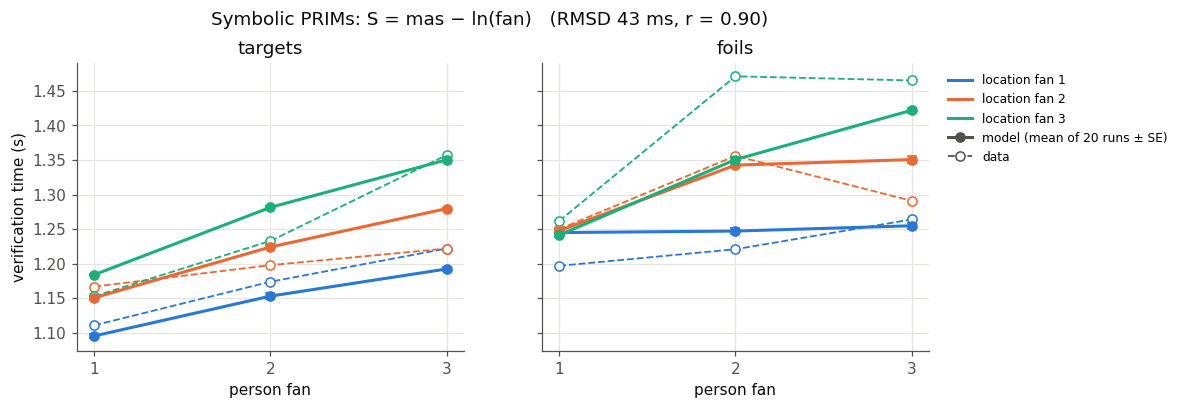

In [6]:
def plot_fit(res, title, ax_pair=None):
    f = res.fit()
    axs = ax_pair if ax_pair is not None else plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)[1]
    for ax, kind in zip(axs, ("target", "foil")):
        for l in (1, 2, 3):
            data = [fan.DATA[kind][(p, l)] for p in (1, 2, 3)]
            model = [res.cells[(kind, p, l)]["rt"] + f["shift"] for p in (1, 2, 3)]
            err = [res.cells[(kind, p, l)]["se"] for p in (1, 2, 3)]
            ax.errorbar([1, 2, 3], model, yerr=err, fmt="-o", color=C[l], ms=6, capsize=3)
            ax.plot([1, 2, 3], data, "--", marker="o", mfc="white", color=C[l], ms=6, lw=1.2)
        ax.set_title(f"{kind}s", color=INK)
        ax.set_xticks([1, 2, 3]); ax.set_xlabel("person fan")
    axs[0].set_ylabel("verification time (s)")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], color=C[l], lw=2, label=f"location fan {l}") for l in (1, 2, 3)]
    handles += [Line2D([], [], color=MUTED, lw=2, marker="o", ms=6, label=f"model (mean of {RUNS} runs ± SE)"),
                Line2D([], [], color=MUTED, lw=1.2, ls="--", marker="o", mfc="white", ms=6, label="data")]
    axs[1].legend(handles=handles, fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.suptitle(f"{title}   (RMSD {1000 * f['rmsd']:.0f} ms, r = {f['r']:.2f})", color=INK, y=1.02)
    return axs

plot_fit(SYM, "Symbolic PRIMs: S = mas − ln(fan)")
plt.show()

The symbolic model captures the main pattern: both fans slow verification, and foils are
slower than targets. It misses the two slowest foil cells (1.471 and 1.465 s, person fan 2 and 3 at
location fan 3) and the dip for person-fan-3 foils at location fan 2.

Averaging matters. With the best parameters a single run fits with an RMSD anywhere
from 38 to 52 ms; with 20 runs the standard error of a cell mean is about 3 ms. A grid
search on single runs would pick parameters partly for their luck.

Two more comparisons with Table 5:

- **The interaction.** Anderson (1974, p. 468) notes that the effect of one fan grows with
  the other: 71, 101 and 186 ms with the other fan at 1, 2 and 3. He took this as
  evidence that the person and the location are searched in parallel. The model shows
  the same over-additive pattern (48, 116 and 168 ms), because retrieval latency
  F·e<sup>−A</sup> multiplies the contributions of the two cues.
- **Errors.** Participants made 5.3% errors on trues and 4.0% on falses; the model makes
  almost none. It has no source of errors at this level of noise, so error rates are not
  fitted here.

## 2. The symbolic limit

The embedded model has a vector for every symbol. In the limit it must be the symbolic
model, which this cell checks *run for run* for five seeds. The settings are random 512-dimensional
vectors, comparisons by similarity ≥ 0.5, partial-matching retrieval with an infinite
mismatch penalty, and similarity-based associations with β = ∞ (explained in section 4).

In [7]:
def limit_rep(seed=0):
    return Embedded(Embedding(dim=512, seed=seed), compare="threshold", theta=0.5,
                    retrieval="soft", mp=math.inf, spreading="similarity", beta=math.inf)

task = fan.make_task(mas=MAS, lf=LF)
same, n = True, 0
for seed in range(5):
    a = fan.run(task, blocks=6, seed=seed)
    b = fan.run(task, representation=limit_rep(seed), blocks=6, seed=seed)
    same &= a == b
    n += len(a)
print("identical trial records:", same, f"({n} trials over 5 runs)")

identical trial records: True (840 trials over 5 runs)


## 3. Does partial matching give a fan effect for free?

A natural first idea is to put the probe in the retrieval request itself
(`V1 -> RT2, V2 -> RT3`) and let partial matching on embeddings do the work: a fact's
activation is reduced by mp · Σ(1 − similarity) over the cue slots. There is then no
spreading from the probe.

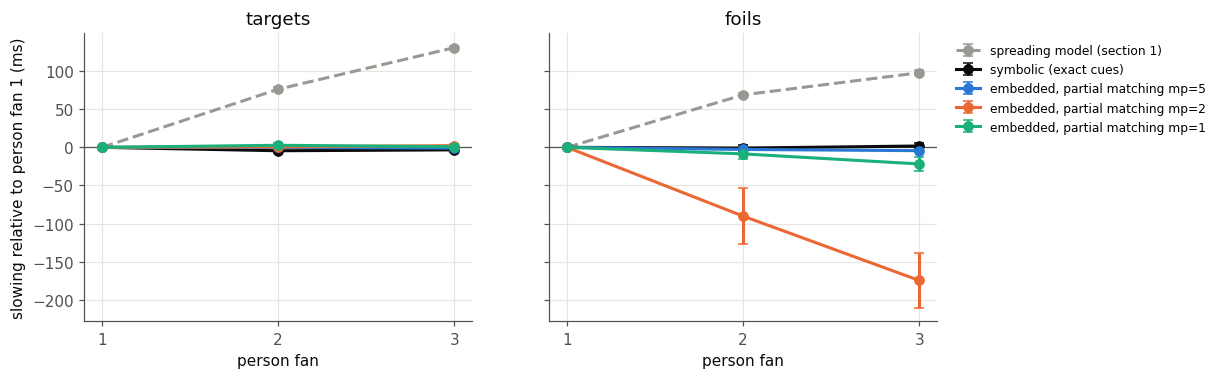

spreading model (section 1)            fan 3 vs 1: targets   +131 ± 2 ms, foils    +98 ± 3 ms; mean foil time 0.67 s
symbolic (exact cues)                  fan 3 vs 1: targets     -3 ± 3 ms, foils     +2 ± 4 ms; mean foil time 4.80 s
embedded, partial matching mp=5        fan 3 vs 1: targets     -1 ± 3 ms, foils     -4 ± 2 ms; mean foil time 4.80 s
embedded, partial matching mp=2        fan 3 vs 1: targets     +2 ± 2 ms, foils   -174 ± 36 ms; mean foil time 4.20 s
embedded, partial matching mp=1        fan 3 vs 1: targets     +1 ± 2 ms, foils    -22 ± 9 ms; mean foil time 1.82 s


In [8]:
variants = {"symbolic (exact cues)": None}
for mp in (5.0, 2.0, 1.0):
    variants[f"embedded, partial matching mp={mp:g}"] = dict(compare="symbolic", retrieval="soft", mp=mp)
pm = {name: many(dict(mas=MAS, lf=LF, cue="slots"), spec) for name, spec in variants.items()}

def slowing(res, kind):
    # per run: mean over location fan, minus person fan 1; then mean and SE over runs
    per_run = []
    for s in res.runs:
        y = [statistics.mean(s[(kind, p, l)]["rt"] for l in (1, 2, 3)) for p in (1, 2, 3)]
        per_run.append([1000 * (v - y[0]) for v in y])
    return ([statistics.mean(r[i] for r in per_run) for i in range(3)],
            [se([r[i] for r in per_run]) for i in range(3)])

curves = {"spreading model (section 1)": SYM, **pm}
shades = ["#9a9893", "#0b0b0b", C[1], C[2], C[3]]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for (name, res), shade in zip(curves.items(), shades):
    for ax, kind in zip(axs, ("target", "foil")):
        y, e = slowing(res, kind)
        ax.errorbar([1, 2, 3], y, yerr=e, marker="o", color=shade, ms=6, capsize=3, label=name,
                    ls="--" if name.startswith("spreading") else "-")
for ax, kind in zip(axs, ("target", "foil")):
    ax.set_title(f"{kind}s", color=INK); ax.set_xticks([1, 2, 3]); ax.set_xlabel("person fan")
    ax.axhline(0, color=MUTED, lw=0.8)
axs[0].set_ylabel("slowing relative to person fan 1 (ms)")
axs[1].legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()
for name, res in curves.items():
    t, te = slowing(res, "target"); f, fe = slowing(res, "foil")
    print(f"{name:38s} fan 3 vs 1: targets {t[2]:+6.0f} ± {te[2]:.0f} ms, foils {f[2]:+6.0f} ± {fe[2]:.0f} ms;"
          f" mean foil time {statistics.mean(v['rt'] for k, v in res.cells.items() if k[0] == 'foil'):.2f} s")

**No.** The spreading model's slowing (grey, dashed) rises with the fan; the
partial-matching models do not:

- **Targets** match the cues exactly and are retrieved equally fast whatever their fan.
- **Foils** have no exact match.
  - Symbolically the retrieval fails, which takes the latency at the retrieval
    threshold (about 5 s here).
  - With embeddings the best partial match is retrieved, at a latency set mainly by
    mp. At mp = 5 that is flat as well.
  - At mp = 2 and mp = 1 foils even show a **reverse** fan effect: −174 ± 36 ms and
    −22 ± 9 ms from person fan 1 to 3. A foil with more facts that share one of its
    cues has more partial matches, and under noise the best of several candidates
    is retrieved sooner (statistical facilitation).

Partial matching scores each fact on its own, so more related facts can only help
retrieval, while the fan effect is a *competition*:
facts sharing a cue divide a limited amount of association. So embeddings do not give
the fan effect for free. They have to enter where the competition is, in the
associations.

## 4. Associations from similarity

ACT-R's S<sub>ji</sub> = mas − ln(fan<sub>j</sub>) is the special case of
S<sub>ji</sub> = mas + ln P(i | j) in which the cue *j* is equally predictive of each of
the fan<sub>j</sub> facts that contain it. With embeddings, P(i | j) can be computed
from similarity:

  P(i | j) = exp(β c<sub>ij</sub>) / Σ<sub>k</sub> exp(β c<sub>kj</sub>),
  S<sub>ji</sub> = max(0, mas + ln P(i | j)),

where c<sub>ij</sub> is how strongly chunk *i* contains *j* (the largest similarity
between *j* and one of *i*'s slot values) and the sum runs over all chunks in memory.

- With **β = ∞** only the chunks that contain *j* itself share the association, and
  S = mas − ln(fan). That is the symbolic model, as section 2 showed.
- With **finite β** every chunk in memory takes a share. For random vectors
  (c ≈ 0 for unrelated chunks) this gives S ≈ mas − ln(fan + N e<sup>−β</sup>), with
  N the number of chunks in memory.

The next cell reads the associations off the running model and compares them with this
closed form.

In [9]:
def assoc_table(beta):
    rep = Embedded(Embedding(512, 0), compare="symbolic", retrieval="symbolic", spreading="similarity", beta=beta)
    m = Model(seed=0, trace=False, batch_mode=True, representation=rep)
    m.load(fan.make_task(mas=MAS, lf=LF))
    N = len(m.dm.chunks) - 1
    out = []
    for person in ("hippie", "giant", "sailor"):                      # fan 1, 2, 3
        j = m.dm.chunks[person]
        i = next(c for c in m.dm.chunks.values() if c.type == "fact" and c.slotvals.get("slot2") is j)
        out.append(rep.sji(j, i))
    return N, out

betas = [math.inf, 12, 8, 6, 4, 3]
print(f"{'beta':>5}   S(fan 1)  S(fan 2)  S(fan 3)    closed form")
for beta in betas:
    N, s = assoc_table(beta)
    cf = [max(0.0, MAS - math.log(f + (N - f) * math.exp(-beta))) if beta != math.inf else MAS - math.log(f)
          for f in (1, 2, 3)]
    print(f"{beta:>5g}   " + "  ".join(f"{x:8.3f}" for x in s) + "    " + "  ".join(f"{x:.3f}" for x in cf))
print(f"\nN = {N} chunks in memory besides the cue itself")

 beta   S(fan 1)  S(fan 2)  S(fan 3)    closed form
  inf      1.500     0.807     0.401    1.500  0.807  0.401
   12      1.500     0.807     0.401    1.500  0.807  0.401
    8      1.478     0.796     0.395    1.482  0.798  0.396
    6      1.355     0.735     0.355    1.377  0.744  0.360
    4      0.764     0.389     0.114    0.822  0.417  0.130
    3      0.148     0.000     0.000    0.208  0.000  0.000

N = 54 chunks in memory besides the cue itself


The closed form holds approximately; random vectors are only nearly orthogonal, which
accounts for the small differences. Now refit the model at several values of β.

β = ∞ is the symbolic model (section 2), so its fits are those of section 1. For the
finite values the grid is refitted, and each β is also compared with the symbolic model
at the *same* mas and lf, run by run with the same seeds (a paired comparison, which
removes most of the run-to-run noise).

In [10]:
fit_betas = [8, 6, 4, 3]
beta_grid = {}
for beta in fit_betas:
    for mas in (1.5, 2.0, 2.5, 3.0):
        for lf_ in (0.6, 0.8, 1.0):
            beta_grid[(beta, mas, lf_)] = many(dict(mas=mas, lf=lf_), similarity_spec(beta))

def describe_fit(res):
    f = res.fit()
    effect = statistics.mean(res.cells[("target", 3, l)]["rt"] - res.cells[("target", 1, l)]["rt"] for l in (1, 2, 3))
    err = statistics.mean(v["err"] for k, v in res.cells.items() if k[0] == "target")
    return f, effect, err

beta_best = {math.inf: ((MAS, LF), SYM)}
for beta in fit_betas:
    cands = {(m_, l_): r for (b, m_, l_), r in beta_grid.items() if b == beta}
    beta_best[beta] = min(cands.items(), key=lambda kv: kv[1].fit()["rmsd"])

sym_runs = SYM.run_rmsds()
print("beta   best mas  lf    RMSD     r    fan effect  errors    vs symbolic at mas/lf of section 1 (paired)")
for beta, ((mas, lf_), res) in beta_best.items():
    f, effect, err = describe_fit(res)
    if beta == math.inf:
        paired = "        (is the symbolic model)"
    else:
        d = [b - a for a, b in zip(sym_runs, beta_grid[(beta, MAS, LF)].run_rmsds())]
        paired = f"   RMSD {1000 * statistics.mean(d):+5.1f} ± {1000 * se(d):.1f} ms per run"
    print(f"{beta:>4g}   {mas:>5.1f}  {lf_:>4.1f}   {1000 * f['rmsd']:4.0f} ms  {f['r']:.2f}   {1000 * effect:5.0f} ms   {err:5.1%}{paired}")

beta   best mas  lf    RMSD     r    fan effect  errors    vs symbolic at mas/lf of section 1 (paired)
 inf     1.5   0.6     43 ms  0.90     131 ms    0.0%        (is the symbolic model)
   8     1.5   0.6     43 ms  0.90     130 ms    0.0%   RMSD  +0.4 ± 0.3 ms per run
   6     1.5   0.6     46 ms  0.88     129 ms    0.1%   RMSD  +2.8 ± 0.9 ms per run
   4     2.0   0.8     50 ms  0.86     104 ms    0.0%   RMSD +13.9 ± 1.2 ms per run
   3     2.0   1.0     51 ms  0.85     118 ms    0.6%   RMSD +181.0 ± 3.1 ms per run


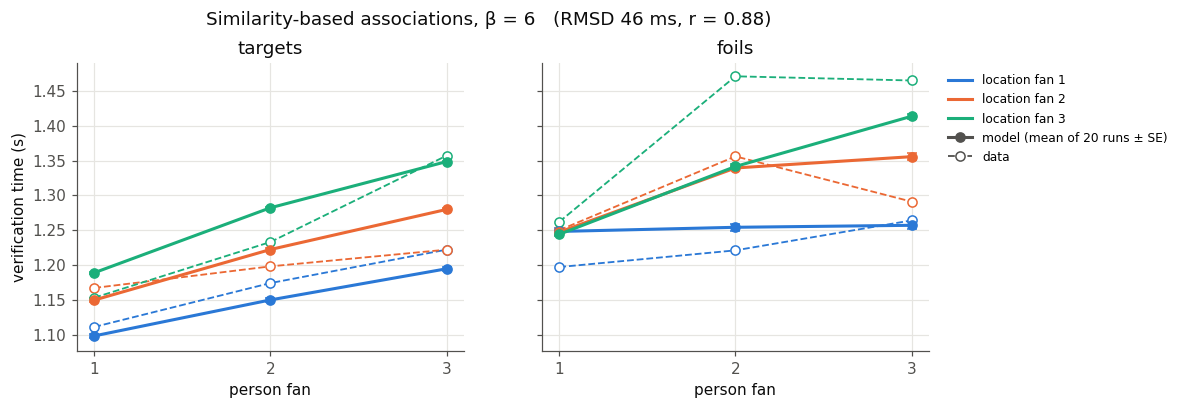

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
plot_fit(beta_best[6][1], "Similarity-based associations, β = 6", ax_pair=axs)
plt.show()

- **β = 8** is indistinguishable from the symbolic model (+0.4 ± 0.3 ms RMSD per run
  at the same parameters).
- **β = 6** is slightly but reliably worse (+2.8 ± 0.9 ms) and selects the same
  parameters; the fan effect is unchanged.
- **Below that**, every chunk in memory takes a noticeable share of the association,
  and the fit degrades even with mas and lf refitted (50 and 51 ms).
  - At β = 4 the person-fan effect shrinks from 131 to 104 ms, because
    ln(fan + c) is flatter than ln(fan).
  - At β = 3 with the symbolic parameters, the associations of fan-2 and fan-3 cues
    drop to zero, hence the large paired difference.

So for unrelated material the data say only that β must be large (about 6 or more),
i.e. the associations must be sharply tuned. The interesting part is what happens when the
material is *not* unrelated, which the symbolic model cannot represent at all.

## 5. What embeddings add

The next experiments take β = 6, the smallest value whose fit is close to the symbolic
model's (3 ms worse per run), with the parameters fitted at that β (mas 1.5, lf 0.6). Each makes some symbols similar
by giving them vectors with a chosen cosine similarity *c*.

In [12]:
BETA = 6.0
(MAS6, LF6), _ = beta_best[BETA]
TASK6 = dict(mas=MAS6, lf=LF6)
print(f"beta = {BETA:g}, mas = {MAS6}, lf = {LF6}")

def probe_effect(person, location, specs, blocks=20, extra_probes=6):
    # For one probe and a list of representation specs: mean correct RT and error rate,
    # each with its SE over runs, plus the slowing relative to the first spec, paired by run.
    pl = fan.probes()
    mine = [p for p in pl if p[0] == person and p[1] == location]
    key = ("target", person, location)
    results = [many(TASK6, spec, blocks=blocks, probe_list=mine + pl[:extra_probes]) for spec in specs]
    base = [r[key]["rt"] for r in results[0].probe_runs]
    out = []
    for res in results:
        rts = [r[key]["rt"] for r in res.probe_runs]
        diff = [1000 * (x - b) for x, b in zip(rts, base) if not (math.isnan(x) or math.isnan(b))]
        out.append(dict(rt=res.probes[key]["rt"], err=res.probes[key]["err"], err_se=res.probes[key]["err_se"],
                        slow=statistics.mean(diff), slow_se=se(diff)))
    return out

beta = 6, mas = 1.5, lf = 0.6


### 5a. Similar cues

Make `hippie` (one fact: *hippie–dungeon*) increasingly similar to `teacher`, who has
three facts and shares no location with the hippie. Symbolically the two are just
different symbols. With similarity-based associations, the cue `hippie` also spreads
to the teacher's facts, so the hippie's own fact gets a smaller share.

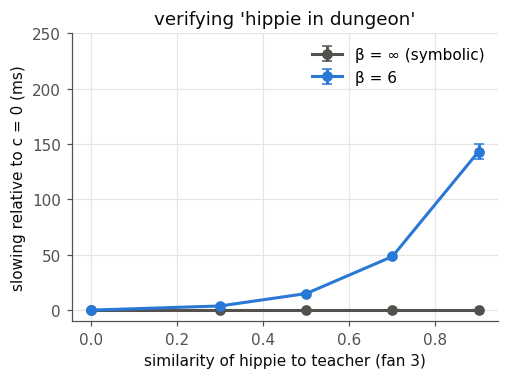

beta inf: c=0.0: +0±0 ms (0% err)  c=0.3: +0±0 ms (0% err)  c=0.5: +0±0 ms (0% err)  c=0.7: +0±0 ms (0% err)  c=0.9: +0±0 ms (0% err)
beta 6: c=0.0: +0±0 ms (0% err)  c=0.3: +4±0 ms (0% err)  c=0.5: +15±0 ms (0% err)  c=0.7: +48±0 ms (0% err)  c=0.9: +143±7 ms (1% err)


In [13]:
cs = [0.0, 0.3, 0.5, 0.7, 0.9]
cue_sim = {beta: probe_effect("hippie", "dungeon",
                              [similarity_spec(beta, similar=[("hippie", "teacher", c)]) for c in cs])
           for beta in (math.inf, BETA)}

fig, ax = plt.subplots(figsize=(5, 3.4))
for beta, shade, label in ((math.inf, MUTED, "β = ∞ (symbolic)"), (BETA, C[1], f"β = {BETA:g}")):
    ax.errorbar(cs, [o["slow"] for o in cue_sim[beta]], yerr=[o["slow_se"] for o in cue_sim[beta]],
                fmt="-o", color=shade, ms=6, capsize=3, label=label)
ax.set_ylim(-10, 250)
ax.set_xlabel("similarity of hippie to teacher (fan 3)"); ax.set_ylabel("slowing relative to c = 0 (ms)")
ax.set_title("verifying 'hippie in dungeon'", color=INK); ax.legend(frameon=False)
plt.show()
for beta, outs in cue_sim.items():
    print(f"beta {beta:g}: " + "  ".join(f"c={c:.1f}: {o['slow']:+.0f}±{o['slow_se']:.0f} ms ({o['err']:.0%} err)"
                                          for c, o in zip(cs, outs)))

With β = ∞ nothing changes, because only identical symbols count. With β = 6 a fan-1 fact
becomes slower to verify as its person becomes similar to a person with many facts.
This is a **similarity-based fan effect**: the effective fan of a cue includes the facts
of similar cues. It is a testable prediction, e.g. with persons that are semantically
related (*doctor*, *nurse*) versus unrelated.

### 5b. Related facts about one person

Now make the sailor's three locations (*museum*, *dungeon*, *forest*) similar to each
other, as if the facts formed a theme, and verify *sailor in museum*.

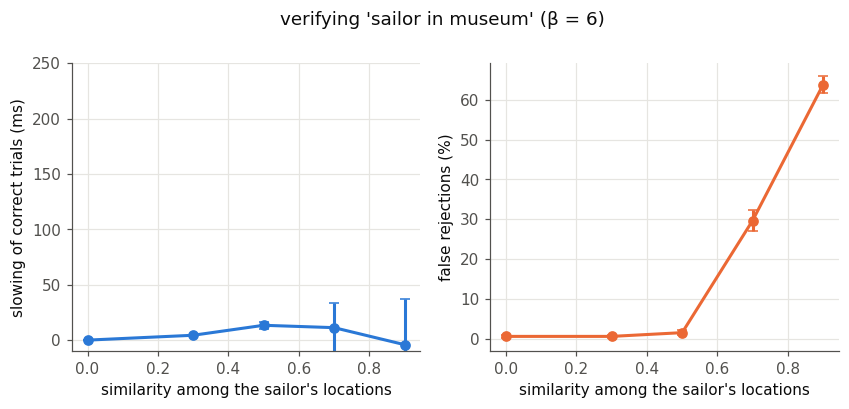

c=0.0: slowing +0 ± 0 ms, 1% ± 0% false rejections
c=0.3: slowing +4 ± 0 ms, 1% ± 0% false rejections
c=0.5: slowing +13 ± 3 ms, 2% ± 1% false rejections
c=0.7: slowing +11 ± 22 ms, 30% ± 3% false rejections
c=0.9: slowing -4 ± 41 ms, 64% ± 2% false rejections


In [14]:
rel = probe_effect("sailor", "museum",
                   [similarity_spec(BETA, similar=[("dungeon", "museum", c), ("forest", "museum", c)]) for c in cs])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].errorbar(cs, [o["slow"] for o in rel], yerr=[o["slow_se"] for o in rel], fmt="-o", color=C[1], ms=6, capsize=3)
axs[0].set_ylim(-10, 250)
axs[0].set_ylabel("slowing of correct trials (ms)")
axs[1].errorbar(cs, [100 * o["err"] for o in rel], yerr=[100 * o["err_se"] for o in rel], fmt="-o",
                color=C[2], ms=6, capsize=3)
axs[1].set_ylabel("false rejections (%)")
for ax in axs:
    ax.set_xlabel("similarity among the sailor's locations")
plt.suptitle(f"verifying 'sailor in museum' (β = {BETA:g})", color=INK, y=1.02)
plt.show()
for c, o in zip(cs, rel):
    print(f"c={c:.1f}: slowing {o['slow']:+.0f} ± {o['slow_se']:.0f} ms, {o['err']:.0%} ± {o['err_se']:.0%} false rejections")

Here the mechanism predicts **more** interference as the facts become related: false
rejections rise from 1% to 30% at c = 0.7 and 64% at c = 0.9. The location cue
*museum* now also spreads to the sailor's *dungeon* and *forest* facts. Those facts
already get the full person cue, so they compete with the target and are often
retrieved instead, giving a false "no". (The correct trials slow by only about 10 ms; at
high similarity they are a selected minority, hence the large error bars.)

That runs against a classic finding: when the facts about a person are thematically
related, the fan effect shrinks or disappears (Smith, Adams & Schorr, 1978; Reder &
Anderson, 1980). So similarity in the associations alone is not the account of
integration. The integration effect needs something that *helps* related facts:

- retrieving the theme instead of the individual fact (a subnode);
- accepting a probe that is consistent with the theme, which graded comparison could
  provide (θ < 1 in `respond-yes`);
- or blending over the related facts.

These are the obvious next experiments.

### 5c. How much else is in memory

With finite β every chunk takes a share of every association, so the *size* of memory
matters, even when it is unrelated material. Add 100 unrelated facts:

In [15]:
extra = [(f"x{k}", "about", f"thing{k}", f"place{k}") for k in range(100)]

def target_means(res):
    rt = [statistics.mean(s[k]["rt"] for k in s if k[0] == "target") for s in res.runs]
    err = [statistics.mean(s[k]["err"] for k in s if k[0] == "target") for s in res.runs]
    return rt, err

print(f"{'beta':>5}   +100 unrelated facts: slowing of targets (paired)   target errors")
for beta in (math.inf, 8.0, BETA):
    base_rt, base_err = target_means(many(TASK6, similarity_spec(beta)))
    more_rt, more_err = target_means(many(dict(TASK6, extra_facts=extra), similarity_spec(beta)))
    d = [1000 * (b - a) for a, b in zip(base_rt, more_rt)]
    print(f"{beta:>5g}   {statistics.mean(d):+6.0f} ± {se(d):.0f} ms"
          f"                              {statistics.mean(base_err):.1%} -> {statistics.mean(more_err):.1%}")

 beta   +100 unrelated facts: slowing of targets (paired)   target errors


  inf       +0 ± 0 ms                              0.0% -> 0.0%


    8      +16 ± 0 ms                              0.0% -> 0.1%


    6     +113 ± 2 ms                              0.1% -> 6.9%


The symbolic model (β = ∞) is indifferent to unrelated material. At finite β, retrieval
slows as memory grows, and at β = 6 errors appear as well, because the targets' share of
the association shrinks towards that of their competitors. Whether people show this beyond what decay already explains is
an empirical question, and β sets the size of the effect.


## 6. Persons resemble persons, locations resemble locations

So far all vectors were random, so any two persons were as unrelated as a person and a
location. More plausibly, a person's vector is somewhat similar to every other person's,
and a location's to every other location's. Here each person gets the vector
√s · u<sub>person</sub> + √(1 − s) · w, with u<sub>person</sub> shared by all persons and
w its own random vector, so any two persons have similarity about *s*; the same holds
for locations, with their own shared component (`fan.make_category`).

With similarity-based associations a person cue now also gives a share to the facts about
*other* persons, with weight e<sup>−β(1−s)</sup> instead of e<sup>−β</sup>. For a fact that
contains the cue this gives

  S ≈ mas − ln(fan + K + N e<sup>−β</sup>),  K = n<sub>other</sub> e<sup>−β(1−s)</sup>,

where n<sub>other</sub> is the number of facts about other persons (or locations). The
shares that go to those other facts are far below e<sup>−mas</sup>, so their S is clipped at
0: the category similarity does not spread activation to other facts. Its only effect is
that K enters every fan, which weakens the associations and compresses the fan effect,
much as a smaller β does. This table shows the associations of a fan-1, fan-2 and fan-3 person:

In [16]:
def category_spec(beta, s_person, s_location, **extra):
    return similarity_spec(beta, categories={"person": (fan.PERSONS, s_person),
                                             "location": (fan.LOCATIONS, s_location)}, **extra)

def own_associations(spec):
    rep = fan.build_representation(spec, seed=0)
    m = Model(seed=0, trace=False, batch_mode=True, representation=rep)
    m.load(fan.make_task(mas=MAS, lf=LF))
    facts = [ch for ch in m.dm.chunks.values() if ch.type == "fact"]
    own, other = [], []
    for person in ("hippie", "giant", "sailor"):                      # fan 1, 2, 3
        j = m.dm.chunks[person]
        own.append(next(rep.sji(j, i) for i in facts if i.slotvals.get("slot2") is j))
        other.append(max(rep.sji(j, i) for i in facts if i.slotvals.get("slot2") is not j))
    return own, max(other)

print(f"mas = {MAS}")
print(" beta    s    S(fan 1)  S(fan 2)  S(fan 3)   largest S to another person's fact   K (fan 1)")
for beta in (8, 12):
    for s in (0, 0.3, 0.5, 0.7):
        own, other = own_associations(category_spec(beta, s, s))
        K = (len(fan.FACTS) - 1) * math.exp(-beta * (1 - s))
        print(f"{beta:>5g}  {s:.1f}   " + "  ".join(f"{x:8.3f}" for x in own) + f"   {other:20.3f}{K:21.3f}")

mas = 1.5
 beta    s    S(fan 1)  S(fan 2)  S(fan 3)   largest S to another person's fact   K (fan 1)
    8  0.0      1.478     0.796     0.395                  0.000                0.008
    8  0.3      1.385     0.753     0.363                  0.000                0.085
    8  0.5      1.038     0.568     0.232                  0.000                0.421
    8  0.7      0.125     0.000     0.000                  0.000                2.087
   12  0.0      1.500     0.807     0.401                  0.000                0.000
   12  0.3      1.493     0.804     0.399                  0.000                0.005
   12  0.5      1.426     0.774     0.378                  0.000                0.057
   12  0.7      0.874     0.470     0.162                  0.000                0.628


The model is refitted (mas and lf) for each combination of β and similarity, with the
similarity applied to both categories, to persons only, or to locations only. Each setting
is also compared, run by run, with the same β without category similarity at the
parameters of section 1.

In [17]:
CAT_BETAS = (8, 12)
CAT_S = (0.3, 0.5, 0.7)
WHICH = {"both": lambda s: (s, s), "persons": lambda s: (s, 0.0), "locations": lambda s: (0.0, s)}
cat_grid = {}
for beta in CAT_BETAS:
    conds = [(0.0, 0.0)] + [WHICH[w](s) for w in WHICH for s in CAT_S]
    for sp, sl in dict.fromkeys(conds):
        for mas in (1.5, 2.0):
            for lf_ in (0.6, 0.8, 1.0):
                cat_grid[(beta, sp, sl, mas, lf_)] = many(dict(mas=mas, lf=lf_), category_spec(beta, sp, sl))

def cat_best(beta, sp, sl):
    cands = {(m_, l_): r for (b, p_, q_, m_, l_), r in cat_grid.items() if (b, p_, q_) == (beta, sp, sl)}
    return min(cands.items(), key=lambda kv: kv[1].fit()["rmsd"])

print("beta  similar     s    best mas  lf    RMSD     r    target errors   vs s = 0 at mas/lf of section 1 (paired)")
for beta in CAT_BETAS:
    base = cat_grid[(beta, 0.0, 0.0, MAS, LF)].run_rmsds()
    for w in ["none"] + list(WHICH):
        for s in ((0.0,) if w == "none" else CAT_S):
            sp, sl = (0.0, 0.0) if w == "none" else WHICH[w](s)
            (mas, lf_), res = cat_best(beta, sp, sl)
            f = res.fit()
            err = statistics.mean(v["err"] for k, v in res.cells.items() if k[0] == "target")
            d = [b - a for a, b in zip(base, cat_grid[(beta, sp, sl, MAS, LF)].run_rmsds())]
            paired = "" if w == "none" else f"   RMSD {1000 * statistics.mean(d):+5.1f} ± {1000 * se(d):.1f} ms per run"
            print(f"{beta:>4g}  {w:9s}  {s:.1f}   {mas:>5.1f}  {lf_:>4.1f}   {1000 * f['rmsd']:4.1f} ms  {f['r']:.3f}   {err:6.1%}{paired}")

beta  similar     s    best mas  lf    RMSD     r    target errors   vs s = 0 at mas/lf of section 1 (paired)
   8  none       0.0     1.5   0.6   43.2 ms  0.896     0.0%
   8  both       0.3     1.5   0.6   44.4 ms  0.890     0.1%   RMSD  +1.4 ± 1.0 ms per run
   8  both       0.5     1.5   0.8   47.8 ms  0.875     1.1%   RMSD  +5.8 ± 1.3 ms per run
   8  both       0.7     2.0   1.0   50.7 ms  0.857     1.0%   RMSD +238.6 ± 8.9 ms per run
   8  persons    0.3     1.5   0.6   37.6 ms  0.923     0.0%   RMSD  -5.0 ± 0.8 ms per run
   8  persons    0.5     1.5   0.6   50.8 ms  0.852     0.4%   RMSD  +8.0 ± 1.5 ms per run
   8  persons    0.7     2.0   0.8   64.0 ms  0.752     0.5%   RMSD +70.0 ± 3.1 ms per run
   8  locations  0.3     1.5   0.6   51.8 ms  0.845     0.0%   RMSD  +9.1 ± 1.6 ms per run
   8  locations  0.5     1.5   0.6   74.1 ms  0.687     0.6%   RMSD +30.4 ± 2.1 ms per run
   8  locations  0.7     2.0   0.6   70.1 ms  0.694     0.5%   RMSD +60.5 ± 1.8 ms per run
  12  non

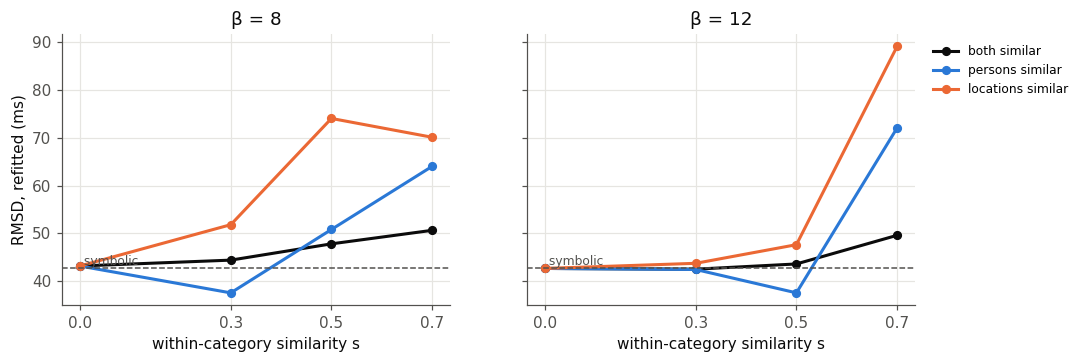

best: beta = 8, s(person) = 0.3, s(location) = 0.0, mas = 1.5, lf = 0.6


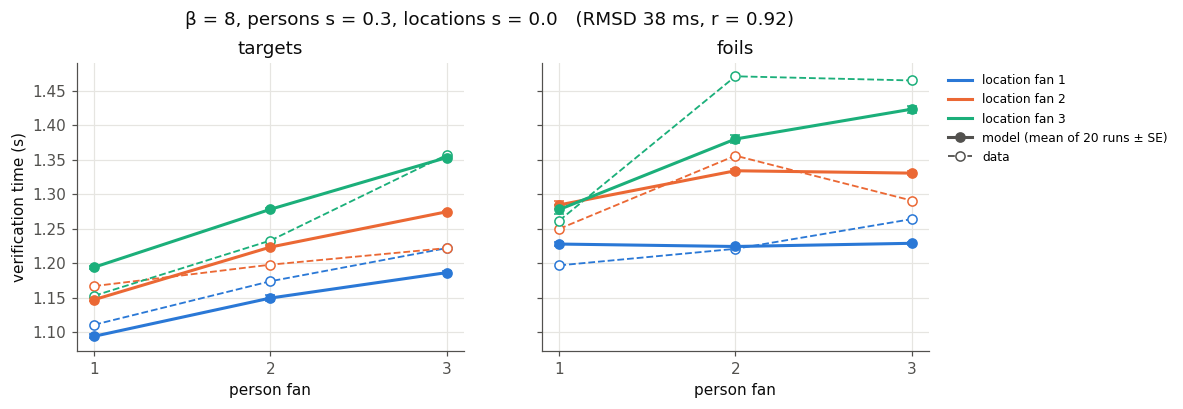

effect of one fan 1 -> 3 with the other at 1 / 2 / 3:  model 61 / 114 / 166 ms


In [18]:
fig, axs = plt.subplots(1, len(CAT_BETAS), figsize=(10, 3.2), sharey=True)
LINE = {"both": INK, "persons": C[1], "locations": C[2]}
for ax, beta in zip(axs, CAT_BETAS):
    zero = 1000 * cat_best(beta, 0.0, 0.0)[1].fit()["rmsd"]
    for w in WHICH:
        ys = [zero] + [1000 * cat_best(beta, *WHICH[w](s))[1].fit()["rmsd"] for s in CAT_S]
        ax.plot((0.0,) + CAT_S, ys, "-o", color=LINE[w], ms=5, label=f"{w} similar")
    ax.axhline(1000 * sym_fit["rmsd"], color=MUTED, ls="--", lw=1)
    ax.text(0.0, 1000 * sym_fit["rmsd"], " symbolic", color=MUTED, va="bottom", fontsize=8)
    ax.set_title(f"β = {beta}", color=INK)
    ax.set_xlabel("within-category similarity s"); ax.set_xticks((0.0,) + CAT_S)
axs[0].set_ylabel("RMSD, refitted (ms)")
axs[-1].legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

best_cat = min(((b, *WHICH[w](s)) for b in CAT_BETAS for w in WHICH for s in CAT_S),
               key=lambda k: cat_best(*k)[1].fit()["rmsd"])
(bm, bl), bres = cat_best(*best_cat)
print(f"best: beta = {best_cat[0]}, s(person) = {best_cat[1]}, s(location) = {best_cat[2]}, mas = {bm}, lf = {bl}")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
plot_fit(bres, f"β = {best_cat[0]}, persons s = {best_cat[1]}, locations s = {best_cat[2]}", ax_pair=axs)
plt.show()
print("effect of one fan 1 -> 3 with the other at 1 / 2 / 3:  model "
      + " / ".join(f"{x:.0f}" for x in interaction(lambda k, p, l: bres.cells[(k, p, l)]["rt"])) + " ms")

**Similarity within both categories does not help.** At β = 12 and s ≤ 0.5 it changes
almost nothing, because K is still small (≤ 0.06). Where K becomes noticeable (β = 8 with
s = 0.5, or s = 0.7), it compresses the fan effect and the fit gets worse, even with
mas and lf refitted. At β = 8 and s = 0.5 it also produces target errors (about 1%,
mostly in the high-fan cells), but the data have about 5% errors in every cell.

**Similarity among the persons alone helps a little.** At β = 8 with s = 0.3, or β = 12
with s = 0.5, the RMSD drops from 43 to 38 ms (−5.0 ± 0.8 and −4.1 ± 0.8 ms per run,
paired), and the interaction moves towards the data (61 / 114 / 166 ms; data 71 / 101 / 186).
Both settings give about the same K (0.09 and 0.06), and that is what matters: a small
offset to the person fans only. Larger values hurt, and similarity among the locations
never helps.

What the offset does shows in the foils. In the symbolic model, a foil with a fan-1
person is rejected at the same speed whatever its location's fan, because the person's
single, strongly associated fact wins the retrieval race. In the data these foils do
slow with the location fan (1.197, 1.250, 1.262 s). Weakening the person associations
lets the location take part in the race. More generally, the data have an asymmetry the
symmetric model lacks: for foils, the location fan matters more than the person fan
(172 against 104 ms in Table 5).

So the gain is real but small, it costs a parameter, and it does not need embeddings:
any mechanism that weakens person associations relative to location associations would
do the same, for instance a separate mas for persons. That persons resemble each other
more than locations do is a possible story, not one these data can establish. Real
embeddings of the words in Anderson's materials could test it, because they would fix the
similarities instead of fitting them.

## Summary

| question | answer |
|---|---|
| symbolic baseline | the fan pattern for targets and foils; RMSD 43 ms, r = 0.90 (mean of 20 runs) |
| symbolic limit | the embedded model at θ = 0.5, mp = ∞, β = ∞ is identical run for run |
| fan effect from partial matching alone? | **no**: flat for targets; for foils flat or even reversed (more partial matches, faster retrieval) |
| associations from similarity, S = mas + ln P<sub>β</sub>(i\|j) | reduces to mas − ln fan at β = ∞; indistinguishable at β = 8, 3 ms worse at β = 6, clearly worse below |
| similar cues | similarity-based fan: a fan-1 fact slows by up to 143 ms when its person resembles a person with many facts |
| related facts | *more* interference (up to 64% false rejections), the opposite of the integration effect, so integration needs another mechanism |
| memory size | at β = 6, 100 unrelated facts add 113 ms and 6.9% errors; the symbolic model predicts no effect |
| persons resemble persons, locations resemble locations | both: no gain, the fan effect compresses; persons only, with a small effective offset: RMSD 43 → 38 ms, through the foils |

**Where embeddings belong, on this evidence.**

- They belong in the **associations** (who competes with whom), not only in matching.
- Taken alone they predict interference from similarity.
- Similarity within a category acts as an offset to the fan. Here it helps only for
  persons and only a little, which a symbolic parameter could do as well.
- Integration effects need a second mechanism that lets related facts help each
  other, such as blending, theme retrieval, or graded acceptance.